# Практическое занятие № 4

### 1. Исходные данные

- y — экспорт в млрд долларов США;
- t — номер квартала от 1 до 24.
- Один сезонный цикл включает l=4 квартала.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Экспорт за 2016–2021
y = np.array([
    4087, 4737, 5768, 6005,
    5639, 6745, 6311, 7107,
    5741, 7087, 7310, 8600,
    6975, 6891, 7527, 7971,
    5875, 6140, 6248, 6041,
    4626, 6501, 6284, 6707
], dtype=float)
t = np.arange(1, len(y) + 1)
l = 4

data = pd.DataFrame({
    "Год": 2016 + (t - 1) // 4,
    "Квартал": (t - 1) % 4 + 1,
    "t": t,
    "Экспорт, млрд долл. США": y
})
display(data)

,Год,Квартал,t,"Экспорт, млрд долл. США"
0,2016,1,1,4087.0
1,2016,2,2,4737.0
2,2016,3,3,5768.0
3,2016,4,4,6005.0
4,2017,1,5,5639.0
5,2017,2,6,6745.0
6,2017,3,7,6311.0
7,2017,4,8,7107.0
8,2018,1,9,5741.0
9,2018,2,10,7087.0


### 2. График временного ряда

Посмотрим, как меняется экспорт, есть ли тенденция и повторяющиеся квартальные колебания.

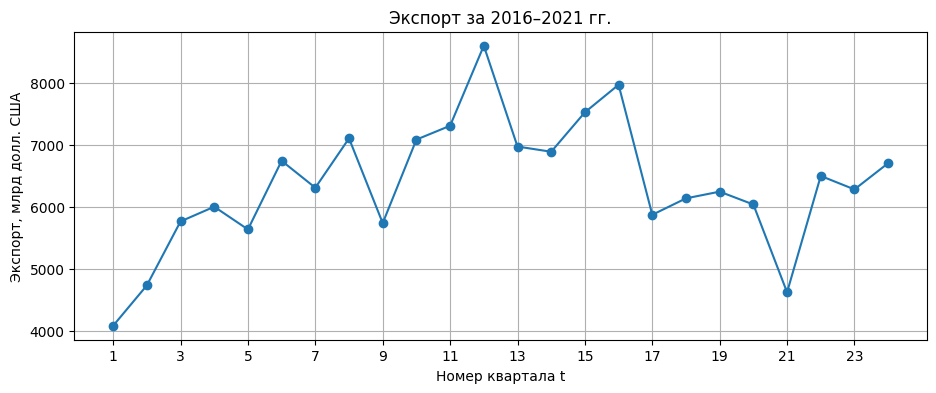

In [ ]:
plt.figure(figsize=(11, 4))
plt.plot(t, y, marker="o")
plt.xticks(t[::2])
plt.xlabel("Номер квартала t")
plt.ylabel("Экспорт, млрд долл. США")
plt.title("Экспорт за 2016–2021 гг.")
plt.grid(True)
plt.show()

Устойчивого линейного тренда на всём интервале нет.

### 3. Аддитивная модель и начальные оценки

Аддитивная модель представляет ряд в виде **суммы** тенденции, сезонной составляющей и случайной ошибки:

$$y_t = a_{1,t} + g_t + \varepsilon_t.$$

- $a_{1,t}$ — тенденции развития; общий уровень экспорта с учётом тренда
- $g_t$ — аддитивный сезонный фактор; насколько квартал обычно отличается от тренда
- $\varepsilon_t$ — случайная ошибка. то, что модель не смогла объяснить

Определим линейный тренд методом наименьших квадратов. МНК выбирает такую прямую, чтобы сумма квадратов отклонений фактических значений от линии тренда была минимальной:

$$\hat y_t = a_1 + a_2 t.$$

Здесь $a_1$ — свободный коэффициент, $a_2$ — изменение тренда за квартал.

Начальные параметры модели рассчитаем по первым 8 кварталам (2016–2017 гг.), то есть по двум полным сезонным циклам. Методом МНК определим начальный тренд, а сезонные составляющие \(g_q\) найдём как средние отклонения фактических значений от тренда для одинаковых кварталов этих двух лет.

Остальные 16 кварталов (2018–2021 гг.) используем для последовательного прогнозирования, обновления модели и расчёта ошибок.

In [ ]:

# Первые 8 кварталов для начальных оценок
n_start = 8

# Начальный линейный тренд методом МНК
a2, a1 = np.polyfit(t[:n_start], y[:n_start], 1)
trend = a1 + a2 * t[:n_start]

# Начальные сезонные эффекты для кварталов 1, 2, 3, 4
residuals_start = y[:n_start] - trend
g = np.array([
    residuals_start[(t[:n_start] - 1) % l == q].mean()
    for q in range(l)
])

# Начальный уровень на конец 8-го квартала
level_start = a1 + a2 * n_start
slope_start = a2

print(f"Начальный тренд: y = {a1:.2f} + {a2:.2f} * t")
print(f"Начальный уровень на t=8: {level_start:.2f}")
print("Начальные сезонные составляющие:")
for q, value in enumerate(g, start=1):
    print(f"  Квартал {q}: {value:.2f}")
print(f"Сумма сезонных составляющих: {g.sum():.8f}")


Начальный тренд: y = 4108.36 + 375.89 * t
Начальный уровень на t=8: 7115.50
Начальные сезонные составляющие:
  Квартал 1: -373.04
  Квартал 2: 129.07
  Квартал 3: 51.68
  Квартал 4: 192.29
Сумма сезонных составляющих: -0.00000000


**Анализ начальных оценок.**

Методом наименьших квадратов получен линейный тренд, который показывает небольшую положительную тенденцию изменения экспорта за рассматриваемый период.

Начальные сезонные составляющие рассчитаны как средние отклонения фактических значений от тренда для одинаковых кварталов разных лет. Сумма сезонных составляющих равна нулю, что соответствует аддитивной модели.

Полученные оценки далее используются для инициализации модели Тейла–Вейджа.

### 4. Адаптивная модель Тейла–Вейджа

Экономика меняется. Экспорт может начать резко расти или падать. Если всё время использовать один и тот же тренд, прогноз постепенно перестанет отражать ситуацию.

Поэтому модель Тейла–Вейджа позволяет обновлять три характеристики (оценки уровня, тренда и сезонности) после каждого квартала.

$0<\alpha_1,\alpha_2,\alpha_3<1$ — параметры сглаживания, $l=4$ — число кварталов в году.

Подберём параметры простым перебором по сетке с шагом 0,05 и выберем сочетание с наименьшей средней квадратической ошибкой (MSE). Перебор здесь используется только для выбора коэффициентов, сам расчёт модели — по формулам выше.

Что делает модель?


1. Берёт **последние оценки** уровня, тренда и нужной сезонности.
2. **Рассчитывает прогноз** очередного квартала.
3. **Сравнивает** прогноз с фактическим экспортом.
4. **Обновляет** уровень, сезонность и тренд с учетом коэффицентов.
5. **Сохраняет** обновлённые значения для следующих кварталов.

In [ ]:

from itertools import product

def model(alpha1, alpha2, alpha3):
    # Начальные параметры на конец 8-го квартала
    level = level_start
    slope = slope_start
    seasons = list(g) * 2
    fitted = []

    # Прогнозы для кварталов 9–24
    for i in range(n_start, len(y)):
        old_season = seasons[i - l]
        predicted = level + slope + old_season
        fitted.append(predicted)

        new_level = alpha1 * (y[i] - old_season) + (1 - alpha1) * (level + slope)
        new_season = alpha2 * (y[i] - new_level) + (1 - alpha2) * old_season
        new_slope = alpha3 * (new_level - level) + (1 - alpha3) * slope

        level, slope = new_level, new_slope
        seasons.append(new_season)

    return np.array(fitted), level, slope, np.array(seasons[-4:])

# Перебор по сетке с шагом 0.05
values = np.arange(0.05, 1.0, 0.05)
best_mse = float("inf")

for alpha1, alpha2, alpha3 in product(values, repeat=3):
    fitted, level, slope, seasons = model(alpha1, alpha2, alpha3)
    mse = np.mean((y[n_start:] - fitted) ** 2)

    if mse < best_mse:
        best_mse = mse
        best_params = (alpha1, alpha2, alpha3)

fitted, level, slope, seasons = model(*best_params)

print("Параметры сглаживания:")
print(f"alpha1 = {best_params[0]:.2f}, alpha2 = {best_params[1]:.2f}, alpha3 = {best_params[2]:.2f}")
print(f"Средняя квадратическая ошибка MSE = {best_mse:.2f}")

# Дополнительные показатели точности
errors = y[n_start:] - fitted

rmse = np.sqrt(best_mse)
mae = np.mean(np.abs(errors))
mape = np.mean(np.abs(errors) / y[n_start:]) * 100

print(f"MAE = {mae:.2f} млрд долл. США")


Параметры сглаживания:
alpha1 = 0.75, alpha2 = 0.85, alpha3 = 0.15
Средняя квадратическая ошибка MSE = 575952.79
MAE = 598.74 млрд долл. США


MSE выражается в квадратных единицах, поэтому для интерпретации дополнительно рассчитаны MAE. Коэффициенты сглаживания подобраны по минимальной MSE на 16 кварталах.

### 5. Прогноз на 2022 год

Продолжим полученную модель на четыре квартала, не изменяя её параметры.

В массиве seasons сохранены последние оценки сезонности для кварталов 1–4.

In [ ]:
tau = np.arange(1, 5)
forecast = level + slope * tau + seasons

result = pd.DataFrame({
    "Год": [2022] * 4,
    "Квартал": tau,
    "t": 24 + tau,
    "Прогноз экспорта, млрд долл. США": np.round(forecast, 2)
})
display(result)
print(f"Прогноз экспорта за весь 2022 год: {forecast.sum():.2f} млрд долл. США")

,Год,Квартал,t,"Прогноз экспорта, млрд долл. США"
0,2022,1,25,5313.63
1,2022,2,26,6347.17
2,2022,3,27,6378.76
3,2022,4,28,6692.62


Прогноз экспорта за весь 2022 год: 24732.18 млрд долл. США


### 6. Сопоставление модели и прогноза с исходными данными

На графике: фактические значения, расчётные значения модели и прогноз на 2022 год.

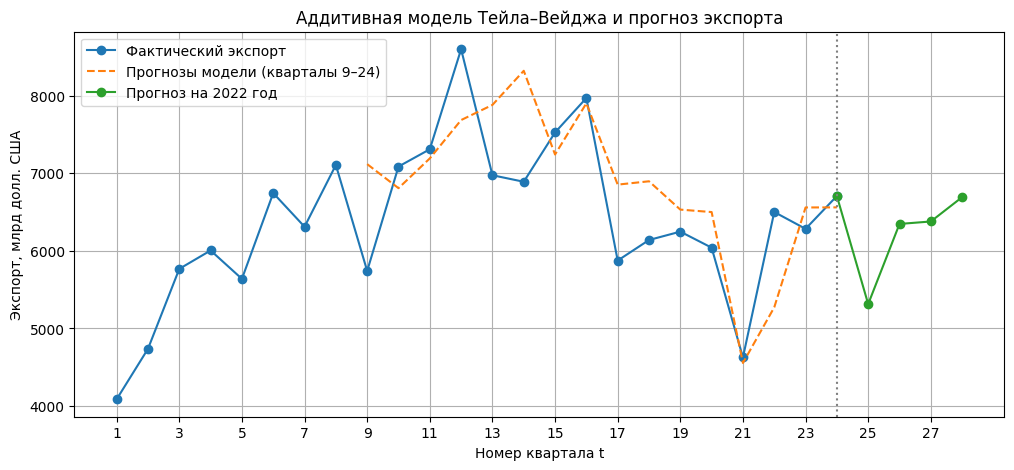

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(t, y, "o-", label="Фактический экспорт")
plt.plot(t[n_start:], fitted, "--", label="Прогнозы модели (кварталы 9–24)")
plt.plot(np.r_[24, 24 + tau], np.r_[y[-1], forecast], "o-", label="Прогноз на 2022 год")
plt.axvline(24, color="gray", linestyle=":")
plt.xticks(np.arange(1, 29, 2))
plt.xlabel("Номер квартала t")
plt.ylabel("Экспорт, млрд долл. США")
plt.title("Аддитивная модель Тейла–Вейджа и прогноз экспорта")
plt.grid(True)
plt.legend()
plt.show()

По данным квартального экспорта за 2016–2021 гг. построена аддитивная модель Тейла—Вейджа с линейным трендом и квартальной сезонностью.

Первые 8 кварталов использованы для расчёта начальных параметров. По остальным 16 кварталам выполнено последовательное прогнозирование с обновлением уровня, тренда и сезонности. Коэффициенты сглаживания подобраны по минимальной MSE.

Получен прогноз экспорта на I–IV кварталы 2022 года.